### Your name:

<pre> Shamir Alavi </pre>

### Collaborators:

<pre> None </pre>


In [1]:
import numpy as np
import pandas as pd

# to make this notebook's output stable across runs
np.random.seed(123)

# To plot pretty figures
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12


### Classification

Q1. Build a classification model for the default of credit card clients dataset. More info here:
https://archive.ics.uci.edu/ml/datasets/default+of+credit+card+clients

- Explore the data
- Make sure you build a full data pipeline
- Do you require any data pre-processing? Are all the features useful? (Use only raw features)
- set the random seed to 123 (For splitting or any other random algorithm)
- Split data into training (80%) and testing (20%)
- Follow similar procedure as the one for week 2 (End-to-end Machine Learning Project). Remember apendix B
- Study the ROC Curve, decide threshold
- Use 2 classifiers.
    - Random Forest
        - tune only: n_estimators: {4, 5, 10, 20, 50} 
    - KNN Classfier 
        - tune only: n_neighbors: {3, 5, 10, 20} 
    - Which one performs better in the cross validation?
    
http://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
http://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

- Cross-validation with 5-folds

- Other paramenters -> Use default

In [2]:
def plot_distribution(df, col, x_label):
    df[col].value_counts().sort_index().plot(
        kind="bar",
        xlabel=x_label,
        ylabel="Number of clients",
        title="Distribution of clients by " + x_label
    )
    plt.tight_layout()
    plt.show()

In [3]:
### Your code here

## Feel free to use multiple cells

import os
import pandas as pd

DATA_PATH = os.path.join('..', 'data')

def load_credit_card_default_data(data_path=DATA_PATH):
    csv_path = os.path.join(data_path, "default_of_credit_card_clients.csv")
    return pd.read_csv(csv_path)

cc_original = load_credit_card_default_data()


## Generate categorical variables

In [4]:
# split sex into categorcal values
cc_original["sex"] = pd.cut(cc_original["SEX"], bins=[-np.inf,1,np.inf], labels=[1,2])

In [5]:
# consolidate other categories into category 4
cc_original["EDUCATION"] = cc_original["EDUCATION"].replace({
    0: 4,
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 4,
    6: 4,
})

# split education into categorcal values
cc_original["education"] = pd.cut(cc_original["EDUCATION"], bins=[-np.inf,1,2,3,np.inf], labels=[1,2,3,4])

In [6]:
# 1 = married; 2 = single; 3 = others
cc_original["MARRIAGE"] = cc_original["MARRIAGE"].replace({
    0: 3,
    1: 1,
    2: 2,
    3: 3
})

# split marriage into categorcal values
cc_original["marriage"] = pd.cut(cc_original["MARRIAGE"], bins=[-np.inf,1,2,np.inf], labels=[1,2,3])

In [7]:
# split age into categorcal values
cc_original["age_group"] = pd.cut(cc_original["AGE"], bins=[-np.inf,29,39,49,59,69,np.inf], labels=[1,2,3,4,5,6])

### Remove duplicate features

In [31]:
cc_original = cc_original.drop(columns=['ID', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE'])
cc_original.columns

Index(['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6',
       'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5',
       'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5',
       'PAY_AMT6', 'default payment next month', 'sex', 'education',
       'marriage', 'age_group'],
      dtype='str')

## Stratified train-test split

In [32]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=123)

for train_index, test_index in split.split(cc_original, cc_original["sex"]):
    strat_train_set_sex = cc_original.loc[train_index]
    strat_test_set_sex = cc_original.loc[test_index]
    
for train_index, test_index in split.split(cc_original, cc_original["education"]):
    strat_train_set_education = cc_original.loc[train_index]
    strat_test_set_education = cc_original.loc[test_index]
    
for train_index, test_index in split.split(cc_original, cc_original["marriage"]):
    strat_train_set_marriage = cc_original.loc[train_index]
    strat_test_set_marriage = cc_original.loc[test_index]
    
for train_index, test_index in split.split(cc_original, cc_original["age_group"]):
    strat_train_set_age_group = cc_original.loc[train_index]
    strat_test_set_age_group = cc_original.loc[test_index]

## Create training pipeline

In [33]:
import time
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder, PowerTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV


# Features
log_cols = [
    "LIMIT_BAL",
    "BILL_AMT1",
    "BILL_AMT2",
    "BILL_AMT3",
    "BILL_AMT4",
    "BILL_AMT5",
    "BILL_AMT6",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

standard_cols = [
    "PAY_0",
    "PAY_2",
    "PAY_3",
    "PAY_4",
    "PAY_5",
    "PAY_6",
    
]

cat_cols = [
    'sex',
    'education',
    'marriage',
    'age_group'
]


# Log transformation + scaling
log_pipeline = Pipeline([
    ("transform", PowerTransformer(method="yeo-johnson")),
    # ("log", FunctionTransformer(lambda x: np.sign(x) * np.log1p(np.abs(x)))),
    ("scale", StandardScaler())
])

# Full preprocessing pipeline for Random Forest
preprocessing_rf = ColumnTransformer([
    ("cat", OneHotEncoder(), cat_cols)
], remainder="passthrough")             # Pass numerical columns as-if to the model

# Full preprocessing pipeline for KNN
preprocessing_knn = ColumnTransformer([
    ("log", log_pipeline, log_cols),
    ("standard", StandardScaler(), standard_cols),
    ("cat", OneHotEncoder(), cat_cols)
])


# Full model pipeline
random_forest = Pipeline([
    ("preprocessing", preprocessing_rf),
    ("rf_classifier", RandomForestClassifier())
])

knn = Pipeline([
    ("preprocessing", preprocessing_knn),
    ("knn_classifier", KNeighborsClassifier())
])


# Grid search
param_grid_rf = {
    "rf_classifier__n_estimators": [4, 5, 10, 20, 50]
}

param_grid_knn = {
    "knn_classifier__n_neighbors": [3, 5, 10, 20]
}

grid_search_rf = GridSearchCV(
    random_forest,
    param_grid_rf,
    cv=5,
    scoring="roc_auc"
)

grid_search_knn = GridSearchCV(
    knn,
    param_grid_knn,
    cv=5,
    scoring="roc_auc"
)

## Run grid search to find the best model and parameters

In [10]:
def run_grid_search(strat_train_set, grid_search, model_name):
    start = time.time()

    grid_search.fit(
        strat_train_set.drop("default payment next month", axis=1),
        strat_train_set["default payment next month"]
    )

    end = time.time()

    print(f"Time taken: {end - start:.2f} seconds")
    print("Best parameters:", grid_search.best_params_)
    print(f"Best CV ROC-AUC {model_name}:", grid_search.best_score_)

    return grid_search

In [34]:
grid_search_rf_sex = run_grid_search(strat_train_set_sex, grid_search_rf, "Random Forest (stratified col: sex)")

Time taken: 27.65 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col: sex): 0.7545581036092704


In [35]:
grid_search_rf_education = run_grid_search(strat_train_set_education, grid_search_rf, "Random Forest (stratified col:education )")

Time taken: 26.56 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col:education ): 0.7546953085364472


In [36]:
grid_search_rf_marriage = run_grid_search(strat_train_set_marriage, grid_search_rf, "Random Forest (stratified col: marriage)")

Time taken: 26.90 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col: marriage): 0.7519884891170477


In [37]:
grid_search_rf_age_group = run_grid_search(strat_train_set_age_group, grid_search_rf, "Random Forest (stratified col: age_group)")

Time taken: 24.87 seconds
Best parameters: {'rf_classifier__n_estimators': 50}
Best CV ROC-AUC Random Forest (stratified col: age_group): 0.7554687291411151


In [38]:
grid_search_knn_sex = run_grid_search(strat_train_set_sex, grid_search_knn, "KNN (stratified col: sex)")

Time taken: 17.55 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col: sex): 0.7495027770826588


In [39]:
grid_search_knn_education = run_grid_search(strat_train_set_education, grid_search_knn, "KNN (stratified col:education )")

Time taken: 19.35 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col:education ): 0.7479495578776605


In [40]:
grid_search_knn_marriage = run_grid_search(strat_train_set_marriage, grid_search_knn, "KNN (stratified col: marriage)")

Time taken: 20.58 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col: marriage): 0.75036056757251


In [41]:
grid_search_knn_age_group = run_grid_search(strat_train_set_age_group, grid_search_knn, "KNN (stratified col: age_group)")

Time taken: 18.86 seconds
Best parameters: {'knn_classifier__n_neighbors': 20}
Best CV ROC-AUC KNN (stratified col: age_group): 0.751027526829908


### Check cross validation scores of both models

In [42]:
results_rf = pd.DataFrame(grid_search_rf.cv_results_)

results_rf[
    [
        "param_rf_classifier__n_estimators",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values("mean_test_score", ascending=False).head(3)

,param_rf_classifier__n_estimators,mean_test_score,std_test_score
4,50,0.755469,0.006666
3,20,0.744609,0.007413
2,10,0.725752,0.008976


In [43]:
results_knn = pd.DataFrame(grid_search_knn.cv_results_)

results_knn[
    [
        "param_knn_classifier__n_neighbors",
        "mean_test_score",
        "std_test_score"
    ]
].sort_values("mean_test_score", ascending=False).head(3)

,param_knn_classifier__n_neighbors,mean_test_score,std_test_score
3,20,0.751028,0.007445
2,10,0.736144,0.007113
1,5,0.705488,0.005123


## Decide ROC threshold using stratified cross validation

#### Generate out-of-fold probabilities

In [44]:
'''
Why pass grid_search_rf instead of grid_search_rf.best_estimator_?

Because grid_search_rf includes the hyperparameter search.
Passing it into cross_val_predict means each outer fold performs its own hyperparameter search using only that fold's training portion.
This avoids using information from the held-out fold during hyperparameter selection.

This is nested cross-validation, so it takes longer to run.
'''


from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Separate features and target
X_train = strat_train_set_age_group.drop(
    "default payment next month", axis=1
)

y_train = strat_train_set_age_group["default payment next month"]

# Define the outer cross-validation folds
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=123
)

# Generate out-of-fold probabilities
y_oof_prob = cross_val_predict(
    grid_search_rf,
    X_train,
    y_train,
    cv=outer_cv,
    method="predict_proba"
)[:, 1]

#### Calculate Youden's J statistic
It calculates 'TPR - FPR' at different probability thresholds to balance the model's ability to identify positive cases against its tendency to incorrectly identify negative cases.

In [45]:
from sklearn.metrics import roc_curve

# Calculate ROC curve using out-of-fold probabilities
fpr, tpr, thresholds = roc_curve(y_train, y_oof_prob)

# Calculate Youden's J
j_scores = tpr - fpr

# Find the threshold with the highest J
best_index = np.argmax(j_scores)
best_threshold = thresholds[best_index]

print("Best threshold:", best_threshold)
print("Best Youden's J:", j_scores[best_index])

Best threshold: 0.2833333333333333
Best Youden's J: 0.40064082288848707


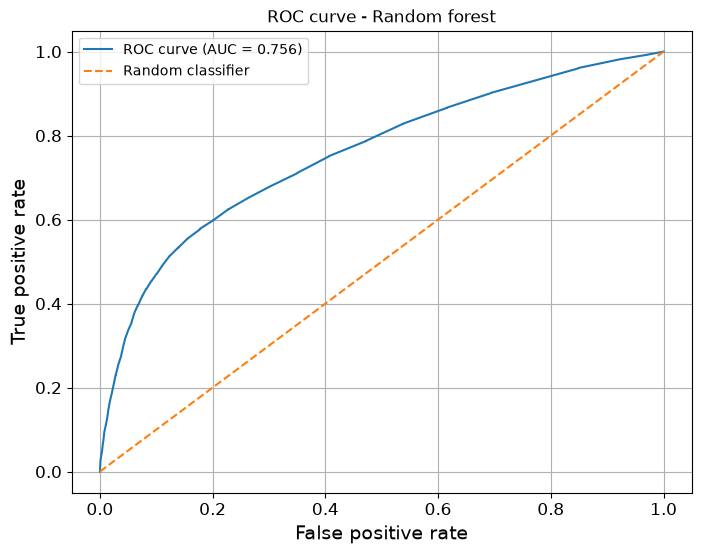

In [46]:
from sklearn.metrics import auc

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve - Random forest")
plt.legend()
plt.grid(True)

plt.show()

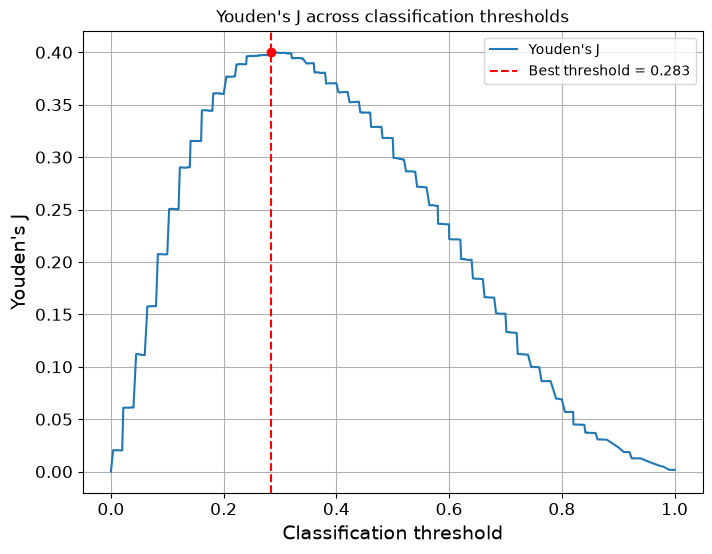

In [47]:
plt.figure(figsize=(8, 6))

plt.plot(thresholds, j_scores, label="Youden's J")

plt.axvline(
    x=best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.3f}"
)

plt.scatter(
    best_threshold,
    j_scores[best_index],
    color="red",
    zorder=5
)

plt.xlabel("Classification threshold")
plt.ylabel("Youden's J")
plt.title("Youden's J across classification thresholds")
plt.legend()
plt.grid(True)

plt.show()

## Apply ROC threshold to evaluate on Test set

In [48]:
'''
y_test_prob contains probabilities, whereas 
y_test_pred contains final binary predictions (0 or 1).
ROC-AUC uses probabilities; other classification metrics use binary predictions.
'''

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Step 1: Separate test features and target
X_test = strat_test_set_age_group.drop(
    "default payment next month", axis=1
)

y_test = strat_test_set_age_group["default payment next month"]

# Step 2: Generate predicted probabilities
y_test_prob = grid_search_rf.best_estimator_.predict_proba(X_test)[:, 1]

# Step 3: Apply Youden's J threshold
y_test_pred = (y_test_prob >= best_threshold).astype(int)

# Step 4: Evaluate model performance
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))
print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1 score:", f1_score(y_test, y_test_pred))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification report:")
print(classification_report(y_test, y_test_pred))

ROC-AUC: 0.7616391442778723
Accuracy: 0.7691666666666667
Precision: 0.4896291640477687
Recall: 0.5761834319526628
F1 score: 0.5293917770981991

Confusion matrix:
[[3836  812]
 [ 573  779]]

Classification report:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      4648
           1       0.49      0.58      0.53      1352

    accuracy                           0.77      6000
   macro avg       0.68      0.70      0.69      6000
weighted avg       0.78      0.77      0.78      6000



#### Conclusions?

Explain your results and choices

**Training and Model selection**

I trained both models on four categories of stratified dataset split (by sex, education, marriage, and age group) to find the best stratum and model. While both models
achived similar performance across all stata, **Random Forest with 50 estimators on dataset split by Education** performed slightly better among all.

Since the largest estimator value achieved the best performance, it tells us that the dataset has enough variance for Random Forest to be effective with the largest 
number of decision trees.

**Finding ROC threshold using Youden's J statistic**

Then I used Stratified 5-fold cross validation on the same training set to predict probabilites (confidence) of the model's prediction. It set the stage to find the 
best ROC threshold using Youden's J statistic.

**Result evaluation**

The result on test set is similar to training set. The model is more confident on predicting who will not be defaulting than predicting who will be defaulting.

Lower AUC on the training set, followed by matching test set results indicates the model underfit the data. Feature engineering performed on the Balance Amount and Pay Amount columns might have provided better results.

**Q2. (Optional)** Write a function that can shift an MNIST image in any direction (left, right, up, or down) by one pixel. Then, for each image in the training set, create four shifted copies (one per direction) and add them to the training set. Finally, train your best model on this expanded training set and measure its accuracy on the test set. You should observe that your model performs even better now! This technique of artificially growing the training set is called data augmentation or training set expansion. 

### Conclusions


### Submit your notebook

Submit your solution here
https://goo.gl/forms/VKD7Zwu54oHjutDc2
Make sure you rename your notebook to    
W3_UTORid.ipynb    
Example W3_adfasd01.ipynb


## Evaluate training vs test result discrepancy

### Check whether the target column or any target-derived feature accidentally appears in X_train or X_test

In [27]:
target = "default payment next month"

print("Target in training features:", target in X_train.columns)
print("Target in test features:", target in X_test.columns)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("Training target distribution:")
print(y_train.value_counts(normalize=True))

print("Test target distribution:")
print(y_test.value_counts(normalize=True))

Target in training features: False
Target in test features: False
Training shape: (24000, 28)
Test shape: (6000, 28)
Training target distribution:
default payment next month
0    0.781042
1    0.218958
Name: proportion, dtype: float64
Test target distribution:
default payment next month
0    0.769833
1    0.230167
Name: proportion, dtype: float64


### Check OOF predictions

In [28]:
from sklearn.metrics import roc_auc_score

print("OOF ROC-AUC:", roc_auc_score(y_train, y_oof_prob))

print("Test ROC-AUC:", roc_auc_score(y_test, y_test_prob))

print("OOF probability range:", y_oof_prob.min(), y_oof_prob.max())
print("Test probability range:", y_test_prob.min(), y_test_prob.max())

OOF ROC-AUC: 0.7597591593724073
Test ROC-AUC: 0.9791320175975597
OOF probability range: 0.0 1.0
Test probability range: 0.0 1.0


### Check whether your feature columns match

In [29]:
print("Same feature columns:",
      X_train.columns.equals(X_test.columns))

print("Training columns:")
print(X_train.columns.tolist())

print("Test columns:")
print(X_test.columns.tolist())

Same feature columns: True
Training columns:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'sex', 'education', 'marriage', 'age_group']
Test columns:
['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'sex', 'education', 'marriage', 'age_group']


#### Findings
Duplicate features: EDUCATION and education etc.

### Check training and test data alignment

In [30]:
# Check whether training and test indices overlap
print("Overlapping indices:",
      len(X_train.index.intersection(X_test.index)))

# Check whether customer IDs overlap
print("Overlapping IDs:",
      len(set(X_train["ID"]).intersection(set(X_test["ID"]))))

# Check whether feature and target indices match
print("Training indices match:",
      X_train.index.equals(y_train.index))

print("Test indices match:",
      X_test.index.equals(y_test.index))

Overlapping indices: 0
Overlapping IDs: 0
Training indices match: True
Test indices match: True
